# Chương 4. Mạng nơ-ron hồi quy (RNN, LSTM) đọc chuỗi lợi suất, kèm backtest

Notebook này gộp hai phần:

- **Phần A: thực nghiệm.** Mạng đọc trực tiếp **20 lợi suất logarit** gần nhất của S&P 500, VN-Index, Bitcoin để đoán phiên kế tiếp
  tăng hay không; so sánh SimpleRNN, LSTM, GRU với hai đường cơ sở; khoảng tin cậy ROC-AUC; **backtest có phí giao dịch**
  so với mua và giữ.
- **Phần B và C: cài đặt.** RNN (phần B) và LSTM (phần C), mỗi mạng **5 lớp hồi quy + 1 Dense**, bằng NumPy tự viết, Keras và PyTorch
  (công thức, từng hàm, huấn luyện).

**Cách đọc.** Đọc ô Markdown trước mỗi ô mã. **Cách chạy.** *Restart Kernel → Run All*, vài phút trên CPU; phần huấn luyện được thu nhỏ
(ghi rõ ở từng mục). Kết quả backtest là mô phỏng trên quá khứ, không phải khuyến nghị đầu tư.

# Phần A · Thực nghiệm RNN/LSTM/GRU và backtest

In [1]:
import os, sys, json, inspect
from pathlib import Path
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '2')          # cùng điều kiện với scripts/tieuluan/run_experiments.py
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
os.environ.setdefault('KERAS_BACKEND', 'tensorflow')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/tieuluan/experiment_models.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score
from src.tieuluan.config import ANALYSIS_START
from src.tieuluan.experiment_models import build_models, fit_model, predict_logits

PROCESSED = ROOT / 'data/tieuluan/processed'
RESULTS = ROOT / 'results/tieuluan/full'
inventory = json.loads((PROCESSED / 'inventory.json').read_text(encoding='utf-8'))
analysis = json.loads((RESULTS / 'analysis.json').read_text(encoding='utf-8'))
provenance = json.loads((ROOT / 'data/tieuluan/provenance.json').read_text(encoding='utf-8'))
records = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(RESULTS.glob('*__*.json'))]
NAMES = {'taiwan_bankruptcy': 'Phá sản DN (UCI 572)', 'credit_default': 'Vỡ nợ thẻ (UCI 350)',
         'sp500': 'S&P 500', 'vnindex': 'VN-Index', 'btc': 'Bitcoin'}
FW = {'scratch': 'NumPy tự viết', 'pytorch': 'PyTorch', 'keras': 'Keras', 'sklearn': 'scikit-learn', 'baseline': 'Đường cơ sở'}
sigmoid = lambda z: .5 * (1 + np.tanh(np.asarray(z, dtype=float) / 2))
print('Số bản ghi thực nghiệm đã lưu:', len(records))

Số bản ghi thực nghiệm đã lưu: 144


In [2]:
DATASETS = ['sp500', 'vnindex', 'btc']
KIND = 'lstm'
KINDS = ['rnn', 'lstm', 'gru', 'persistence', 'majority']
REPRESENTATION = 'sequence'
DEMO = 'vnindex'

## A1. Dữ liệu

Kích thước và phân bố lớp đọc trực tiếp từ mảng đã lưu (không chép tay). Bộ tiền xử lý (chuẩn hóa,
điền khuyết) chỉ học trên tập train rồi áp dụng nguyên cho validation và test.

In [3]:
data = {}
rows = []
for name in DATASETS:
    with np.load(PROCESSED / f'{name}.npz', allow_pickle=False) as archive:
        data[name] = {key: archive[key] for key in archive.files}
    for split in ('train', 'val', 'test'):
        y = data[name][f'{split}_y']
        assert len(y) == inventory[name]['splits'][split]['n']          # khớp số liệu đã kiểm kê
        rows.append({'Bộ dữ liệu': NAMES[name], 'Tập': split, 'Số mẫu': len(y), 'Lớp 0': int((y == 0).sum()),
                     'Lớp 1': int((y == 1).sum()), 'Tỉ lệ lớp 1': round(float(y.mean()), 4),
                     'Kích thước đầu vào': str(data[name][f'{split}_{REPRESENTATION}'].shape[1:])})
display(pd.DataFrame(rows))

,Bộ dữ liệu,Tập,Số mẫu,Lớp 0,Lớp 1,Tỉ lệ lớp 1,Kích thước đầu vào
0,S&P 500,train,5010,2327,2683,0.5355,"(20, 1)"
1,S&P 500,val,755,360,395,0.5232,"(20, 1)"
2,S&P 500,test,938,418,520,0.5544,"(20, 1)"
3,VN-Index,train,2473,1155,1318,0.5330,"(20, 1)"
4,VN-Index,val,750,318,432,0.5760,"(20, 1)"
5,VN-Index,test,929,408,521,0.5608,"(20, 1)"
6,Bitcoin,train,1911,866,1045,0.5468,"(20, 1)"
7,Bitcoin,val,1095,533,562,0.5132,"(20, 1)"
8,Bitcoin,test,1368,682,686,0.5015,"(20, 1)"


In [4]:
PAGES = {'sp500': 'https://finance.yahoo.com/quote/%5EGSPC/history/ (Yahoo Finance, ^GSPC)', 'vnindex': 'https://iboard.ssi.com.vn/ (SSI iBoard; bổ sung DNSE Entrade, đối chiếu VNDirect)', 'btc': 'https://finance.yahoo.com/quote/BTC-USD/history/ (Yahoo Finance, BTC-USD)'}

rows_l = []
for name in DATASETS:
    key = f'raw/uci/{name}' if name in ('taiwan_bankruptcy', 'credit_default') else f'raw/indices/{name}.csv'
    meta = provenance.get(key, {})
    rows_l.append({'Bộ dữ liệu': NAMES[name], 'Liên kết nguồn': PAGES[name],
                   'Tải về lúc (UTC)': str(meta.get('downloaded_at', ''))[:19].replace('T', ' ')})
pd.set_option('display.max_colwidth', 120)
display(pd.DataFrame(rows_l))

,Bộ dữ liệu,Liên kết nguồn,Tải về lúc (UTC)
0,S&P 500,"https://finance.yahoo.com/quote/%5EGSPC/history/ (Yahoo Finance, ^GSPC)",2026-10-05 16:23:05
1,VN-Index,"https://iboard.ssi.com.vn/ (SSI iBoard; bổ sung DNSE Entrade, đối chiếu VNDirect)",2026-10-06 10:40:52
2,Bitcoin,"https://finance.yahoo.com/quote/BTC-USD/history/ (Yahoo Finance, BTC-USD)",2026-10-05 16:23:10


**Dòng dữ liệu gốc và kiểm tra ranh giới thời gian.** Train gồm các mẫu có ngày nhãn đến hết 2019, validation
2020–2022, test từ 01/2023 đến 30/09/2026; mẫu có nhãn vượt sang tập sau bị loại. Ô dưới kiểm tra lại điều đó.

In [5]:
for name in DATASETS:
    raw = pd.read_csv(ROOT / f'data/tieuluan/raw/indices/{name}.csv')
    raw = raw[raw.date >= ANALYSIS_START[name]]
    print(f"{NAMES[name]}: {len(raw)} phiên từ {raw.date.iloc[0]} đến {raw.date.iloc[-1]}")
    display(raw.head(3))
    arrays = data[name]
    assert arrays['train_target_date'].max() <= np.datetime64('2019-12-31')
    assert arrays['val_date'].min() >= np.datetime64('2020-01-01')
    assert arrays['val_target_date'].max() <= np.datetime64('2022-12-31')
    assert arrays['test_date'].min() >= np.datetime64('2023-01-01')
    assert arrays['test_target_date'].max() <= np.datetime64('2026-09-30')
print('Đã kiểm tra: không mẫu nào có nhãn vượt ranh giới giữa các tập.')

S&P 500: 6726 phiên từ 2000-01-03 đến 2026-09-30


,date,open,high,low,close,volume,source
0,2000-01-03,1469.250000,1478.000000,1438.359985,1455.219971,931800000,Yahoo Finance
1,2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,1009000000,Yahoo Finance
2,2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,1085500000,Yahoo Finance


VN-Index: 4175 phiên từ 2010-01-04 đến 2026-09-30


,date,open,high,low,close,volume,source
2192,2010-01-04,501.7,517.1,501.7,517.1,42051600,SSI iBoard
2193,2010-01-05,538.8,539.4,530.2,532.5,66619450,SSI iBoard
2194,2010-01-06,527.4,538.8,526.4,534.5,64222280,SSI iBoard


Bitcoin: 4397 phiên từ 2014-09-17 đến 2026-09-30


,date,open,high,low,close,volume,source
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,21056800,Yahoo Finance
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,34483200,Yahoo Finance
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,37919700,Yahoo Finance


Đã kiểm tra: không mẫu nào có nhãn vượt ranh giới giữa các tập.


**Chuỗi lợi suất.** Đầu vào của mạng hồi quy là 20 lợi suất logarit gần nhất, chuẩn hóa bằng trung bình và độ
lệch chuẩn của tập train. Biểu đồ khôi phục về đơn vị phần trăm để dễ đọc.

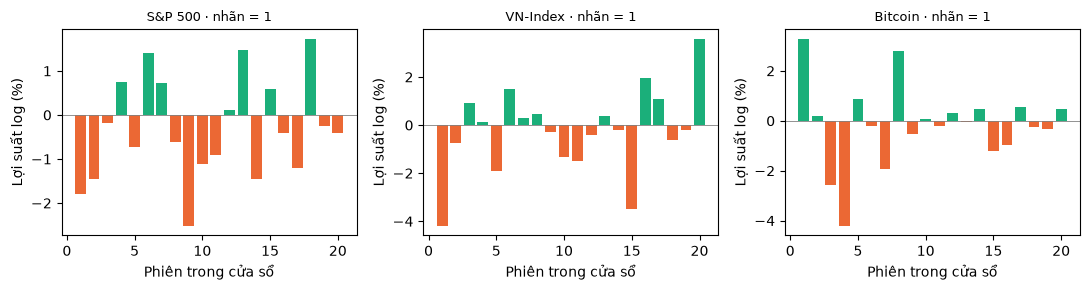

In [6]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 3))
for ax, name in zip(axes, DATASETS):
    arrays = data[name]
    r = arrays['test_sequence'][0, :, 0] * arrays['scaler_scale'][0] + arrays['scaler_mean'][0]
    ax.bar(np.arange(1, 21), 100 * r, color=np.where(r > 0, '#1baf7a', '#eb6834'))
    ax.axhline(0, color='gray', lw=.6)
    ax.set_title(f"{NAMES[name]} · nhãn = {int(arrays['test_y'][0])}", fontsize=9)
    ax.set_xlabel('Phiên trong cửa sổ'); ax.set_ylabel('Lợi suất log (%)')
plt.tight_layout(); plt.show()

**Nhận xét về dữ liệu.** Tỉ lệ nhãn “tăng” ở train / validation / test lần lượt là S&P 500 53,6% / 52,3% / 55,4%; VN-Index 53,3% / 57,6% / 56,1%; Bitcoin 54,7% / 51,3% / 50,1%. Các tỉ lệ đều trên 50%, nên một mô hình “luôn đoán tăng” đã đạt accuracy trên 50% mà không học gì; đó là lý do báo cáo dùng ROC-AUC và so với đường cơ sở. Dữ liệu chia theo thời gian nên tập test (2023 đến 09/2026) là giai đoạn mô hình chưa từng thấy, và mẫu có nhãn vượt ranh giới giữa các tập đã bị loại.

## A2. Một mô hình, ba cách cài đặt

Mã nguồn đầy đủ nằm trong `src/tieuluan/experiment_models.py` (hàm `scratch_model`, `torch_model`, `keras_model`)
và thư viện tự viết `src/tieuluan/scratch/`. Ô dưới in phần định nghĩa mô hình của ba hàm, rồi khởi tạo cả ba
bản bằng **cùng một bộ trọng số NumPy** và so sánh logit đầu ra trên vài mẫu (chưa huấn luyện).

In [7]:
import src.tieuluan.experiment_models as em
for fn in (em.scratch_model, em.torch_model, em.keras_model):
    print(inspect.getsource(fn))

def scratch_model(kind, input_shape, seed):
    rng = np.random.default_rng(seed)
    if kind == "mlp":
        return Sequential(Dense(input_shape[0], 16, rng=rng), ReLU(), Dense(16, 1, rng=rng))
    if kind in ("cnn4", "cnn8"):
        filters = 8 if kind == "cnn8" else 4
        return Sequential(Conv2d(1, filters, 3, rng=rng), ReLU(), MaxPool2d(2),       # 20 → 18 → 9
                          Flatten(), Dense(filters * 9 * 9, 1, rng=rng))
    if kind == "cnndeep":
        return Sequential(Conv2d(1, 4, 3, rng=rng), ReLU(), MaxPool2d(2),             # 20 → 18 → 9
                          Conv2d(4, 8, 3, rng=rng), ReLU(), MaxPool2d(2),             # 9 → 7 → 3
                          Flatten(), Dense(8 * 3 * 3, 1, rng=rng))
    cell = {"rnn": SimpleRNN, "lstm": LSTM, "gru": GRU}[kind]
    return Sequential(cell(input_shape[-1], HIDDEN, rng=rng), LastStep(), Dense(HIDDEN, 1, rng=rng))

def torch_model(kind, input_shape):
    import torch
    from torch import nn

    torch.set_num_

In [8]:
sample = data[DEMO]['train_' + REPRESENTATION][:8].astype(np.float32)
models = build_models(KIND, sample.shape[1:], seed=11)
logits = {FW[f]: predict_logits(m, f, sample) for f, m in models.items()}
display(pd.DataFrame(logits).round(6))
base = logits['NumPy tự viết']
print({k: float(np.max(np.abs(v - base))) for k, v in logits.items()}, '← lệch tuyệt đối lớn nhất so với NumPy')

,NumPy tự viết,PyTorch,Keras
0,0.091025,0.091025,0.091025
1,0.070543,0.070543,0.070543
2,-0.000623,-0.000623,-0.000623
3,-0.051960,-0.051960,-0.051960
4,0.145073,0.145073,0.145073
5,0.129251,0.129251,0.129251
6,0.168839,0.168839,0.168839
7,0.100390,0.100390,0.100390


{'NumPy tự viết': 0.0, 'PyTorch': 4.470348358154297e-08, 'Keras': 2.2351741790771484e-08} ← lệch tuyệt đối lớn nhất so với NumPy


### A2.1. Mã nguồn tự viết bằng NumPy

Ô dưới in mã của các lớp tự viết mà mô hình của chương sử dụng. Mỗi lớp tự cài `forward` (lan truyền xuôi) và
`backward` (lan truyền ngược) bằng công thức đạo hàm; không có autograd nào được dùng. Thư viện đầy đủ nằm ở
`src/tieuluan/scratch/` (còn có Conv2d, MaxPool2d, BatchNorm, Dropout, SimpleRNN, LSTM, GRU, SGD, Adam).

In [9]:
import importlib
CLASSES = ['recurrent.LSTM', 'recurrent.LastStep', 'layers.Dense', 'optim.Adam']
for path in CLASSES:
    module, name = path.split('.')
    print(inspect.getsource(getattr(importlib.import_module('src.tieuluan.scratch.' + module), name)))

class LSTM(_Recurrent):
    """LSTM (Hochreiter & Schmidhuber, 1997; cổng quên của Gers et al., 2000).

    i = σ(·), f = σ(·), g = tanh(·), o = σ(·);  c_t = f⊙c_{t-1} + i⊙g;  h_t = o⊙tanh(c_t).
    """

    gates = 4

    def __init__(self, input_size, hidden_size, *, rng=None, dtype=np.float32, forget_bias: float = 1.0):
        super().__init__(input_size, hidden_size, rng=rng, dtype=dtype, forget_bias=forget_bias)

    def forward(self, x):
        n, t_len, _ = x.shape
        hd = self.hidden_size
        xw = x @ self.weight_ih.value.T + self.bias_ih.value
        h = np.zeros((n, hd), dtype=x.dtype)
        c = np.zeros((n, hd), dtype=x.dtype)
        hs = np.empty((n, t_len + 1, hd), dtype=x.dtype); hs[:, 0] = h
        cs = np.empty((n, t_len + 1, hd), dtype=x.dtype); cs[:, 0] = c
        acts = np.empty((n, t_len, 4 * hd), dtype=x.dtype)
        tcs = np.empty((n, t_len, hd), dtype=x.dtype)
        for t in range(t_len):
            z = xw[:, t] + h @ self.weight_hh.value.T 

### A2.2. Bước huấn luyện của ba cách cài đặt

Mỗi cách có một lớp huấn luyện với phương thức `step` thực hiện một bước cập nhật trên một mini-batch: NumPy gọi
`backward` tự viết rồi `Adam` tự viết; PyTorch dùng `loss.backward()` và `torch.optim.Adam`; Keras dùng
`train_on_batch`. Cả ba cùng dùng Adam và cắt chuẩn gradient toàn cục ở mức 1,0.

In [10]:
import src.tieuluan.experiment_models as em
for cls in (em.ScratchTrainer, em.TorchTrainer, em.KerasTrainer):
    print(inspect.getsource(cls))

class ScratchTrainer:
    """NumPy: forward → loss → backward (tự viết) → cắt gradient → Adam (tự viết)."""

    def __init__(self, model, kind):
        self.model = model
        self.params = [p for p in model.parameters() if not (kind in ("rnn", "lstm") and p.name == "bias_hh")]
        self.optimizer = Adam(self.params, lr=1e-3, eps=1e-8)
        self.loss_fn = BCEWithLogitsLoss()

    def step(self, xb, yb):
        self.model.train()
        self.model.zero_grad()
        logits = self.model.forward(xb)
        loss = self.loss_fn.forward(logits, yb)
        self.model.backward(self.loss_fn.backward())
        clip_grad_norm(self.params, 1.0)
        self.optimizer.step()
        return loss

class TorchTrainer:
    """PyTorch: loss.backward() do autograd tính; torch.optim.Adam cập nhật."""

    def __init__(self, model, kind):
        import torch

        self.torch = torch
        self.model = model
        self.params = [p for p in model.parameters() if p.requires_grad]
    

## A3. Huấn luyện lại bằng ba cách (vnindex, hạt giống 11, bản rút gọn)

Cả ba bản dùng cùng trọng số khởi tạo, cùng thứ tự mini-batch (batch 64), Adam (lr 0,001), cắt chuẩn gradient 1,0.
**Để notebook chạy trong vài phút, ở đây chỉ huấn luyện tối đa 12 epoch** (dừng sớm sau 4 epoch không cải thiện),
trong khi kết quả đã lưu của báo cáo dùng tối đa 60 epoch. Vì vậy ROC-AUC vừa huấn luyện có thể khác bản đầy đủ chút ít; cột
"lệch xác suất" so với bản đầy đủ lớn hơn là bình thường. Điều cần kiểm tra là ba cách cài đặt cho kết quả gần nhau.

,Cài đặt,Epoch tốt nhất,Số epoch đã chạy,Giây,ROC-AUC vừa huấn luyện,ROC-AUC bản đầy đủ đã lưu,Lệch xác suất tối đa so với bản đầy đủ đã lưu
0,NumPy tự viết,8,12,4.9,0.54554,0.54554,0.0
1,PyTorch,8,12,2.6,0.54554,0.54554,0.0
2,Keras,8,12,13.2,0.54553,0.54553,0.0


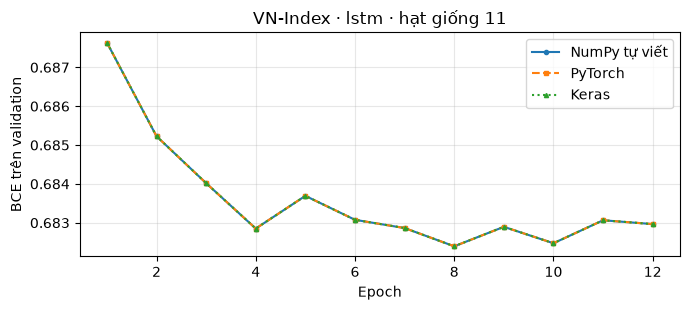

In [11]:
x, y = data[DEMO]['train_' + REPRESENTATION], data[DEMO]['train_y']
xv, yv = data[DEMO]['val_' + REPRESENTATION], data[DEMO]['val_y']
xt, yt = data[DEMO]['test_' + REPRESENTATION], data[DEMO]['test_y']
saved = {r['framework']: r for r in records if r['dataset'] == DEMO and r['kind'] == KIND and r['seed'] == 11}
rows, curves = [], {}
for framework in ('scratch', 'pytorch', 'keras'):
    model = build_models(KIND, x.shape[1:], seed=11, frameworks=(framework,))[framework]
    fit = fit_model(model, framework, KIND, x, y, xv, yv, seed=11, epochs=12, batch_size=64, patience=4)
    p = sigmoid(predict_logits(model, framework, xt))
    with np.load(RESULTS / f'{DEMO}__{KIND}__{framework}__11_predictions.npz') as archive:
        p_saved = archive['probability']
    curves[framework] = [h['val_loss'] for h in fit['history']]
    rows.append({'Cài đặt': FW[framework], 'Epoch tốt nhất': fit['best_epoch'], 'Số epoch đã chạy': fit['epochs_run'],
                 'Giây': round(fit['training_seconds'], 1), 'ROC-AUC vừa huấn luyện': round(roc_auc_score(yt, p), 5),
                 'ROC-AUC bản đầy đủ đã lưu': round(saved[framework]['metrics']['roc_auc'], 5),
                 'Lệch xác suất tối đa so với bản đầy đủ đã lưu': float(np.max(np.abs(p - p_saved)))})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(figsize=(7, 3.2))
for (framework, values), style in zip(curves.items(), ('-o', '--s', ':^')):
    ax.plot(range(1, len(values) + 1), values, style, ms=3, label=FW[framework])
ax.set_xlabel('Epoch'); ax.set_ylabel('BCE trên validation'); ax.set_title(f'{NAMES[DEMO]} · {KIND} · hạt giống 11')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

**Đọc kết quả.** Ba cách cài đặt cho ROC-AUC trùng nhau đến 4–5 chữ số (vì cùng trọng số khởi tạo và thứ tự mini-batch), và bản rút gọn 12 epoch trùng bản đầy đủ đã lưu vì cả hai dừng sớm ở cùng epoch. LSTM trên VN-Index đạt ROC-AUC khoảng 0,546: cao hơn 0,5 chút ít, nhưng đây là một lần huấn luyện; mục A4 cho khoảng tin cậy và ba hạt giống.

## A4. Kết quả đầy đủ (3 hạt giống) và khoảng tin cậy

Bảng dưới tổng hợp các bản ghi đã lưu của chương (trung bình và độ lệch chuẩn qua 3 hạt giống), tiếp theo là
khoảng tin cậy 95% của ROC-AUC cho dự báo trung bình 3 hạt giống.

In [12]:
rows = []
for r in records:
    if r['dataset'] in DATASETS and r['kind'] in KINDS:
        rows.append({'Bộ dữ liệu': NAMES[r['dataset']], 'Mô hình': r['kind'], 'Cài đặt': FW[r['framework']],
                     'roc_auc': r['metrics']['roc_auc'], 'balanced_accuracy': r['metrics']['balanced_accuracy']})
table = (pd.DataFrame(rows).groupby(['Bộ dữ liệu', 'Mô hình', 'Cài đặt'])
         .agg(ROC_AUC_TB=('roc_auc', 'mean'), ROC_AUC_ĐLC=('roc_auc', 'std'),
              Balanced_acc=('balanced_accuracy', 'mean'), Số_lượt=('roc_auc', 'size')).round(4))
display(table)

ROC_AUC_TB  ROC_AUC_ĐLC  Balanced_acc  \
Bộ dữ liệu Mô hình     Cài đặt                                                
Bitcoin    gru         PyTorch            0.5172       0.0079        0.5051   
           lstm        Keras              0.5047       0.0214        0.5069   
                       NumPy tự viết      0.5047       0.0214        0.5069   
                       PyTorch            0.5047       0.0214        0.5069   
           majority    Đường cơ sở        0.5000          NaN        0.5000   
           persistence Đường cơ sở        0.4846          NaN        0.4846   
           rnn         PyTorch            0.5106       0.0039        0.5162   
S&P 500    gru         PyTorch            0.4904       0.0011        0.4909   
           lstm        Keras              0.4962       0.0035        0.4947   
                       NumPy tự viết      0.4962       0.0035        0.4947   
                       PyTorch            0.4962       0.0035        0.4947   
           majority    Đường cơ sở        0.5000          NaN        0.5000   
           persistence Đường cơ sở        0.4929          NaN        0.4929   
           rnn         PyTorch            0.4960       0.0067        0.4972   
VN-Index   gru         PyTorch            0.5441       0.0034        0.5302   
           lstm        Keras              0.5443       0.0011        0.5405   
                       NumPy tự viết      0.5443       0.0011        0.5405   
                       PyTorch            0.5443       0.0011        0.5405   
           majority    Đường cơ sở        0.5000          NaN        0.5000   
           persistence Đường cơ sở        0.5180          NaN        0.5180   
           rnn         PyTorch            0.5252       0.0203        0.5119   

                                      Số_lượt  
Bộ dữ liệu Mô hình     Cài đặt                 
Bitcoin    gru         PyTorch              3  
           lstm        Keras                3  
                       NumPy tự viết        3  
                       PyTorch              3  
           majority    Đường cơ sở          1  
           persistence Đường cơ sở          1  
           rnn         PyTorch              3  
S&P 500    gru         PyTorch              3  
           lstm        Keras                3  
                       NumPy tự viết        3  
                       PyTorch              3  
           majority    Đường cơ sở          1  
           persistence Đường cơ sở          1  
           rnn         PyTorch              3  
VN-Index   gru         PyTorch              3  
           lstm        Keras                3  
                       NumPy tự viết        3  
                       PyTorch              3  
           majority    Đường cơ sở          1  
           persistence Đường cơ sở          1  
           rnn         PyTorch              3

In [13]:
rows = [{'Chỉ số': NAMES[name], 'Mô hình': key, 'ROC-AUC': round(item['auc'], 4), 'CI 95% thấp': round(item['low'], 4),
         'CI 95% cao': round(item['high'], 4), 'p (AUC ≤ 0,5)': round(item['p_value_auc_le_half'], 3)}
        for name in DATASETS for key, item in analysis['auc_ci'][name].items() if key in KINDS]
display(pd.DataFrame(rows))

,Chỉ số,Mô hình,ROC-AUC,CI 95% thấp,CI 95% cao,"p (AUC ≤ 0,5)"
0,S&P 500,persistence,0.4929,0.4620,0.5193,0.728
1,S&P 500,rnn,0.4959,0.4610,0.5275,0.618
2,S&P 500,lstm,0.4962,0.4609,0.5306,0.571
3,S&P 500,gru,0.4902,0.4544,0.5248,0.702
4,VN-Index,persistence,0.5180,0.4875,0.5509,0.127
5,VN-Index,rnn,0.5294,0.4930,0.5632,0.061
6,VN-Index,lstm,0.5445,0.5060,0.5735,0.010
7,VN-Index,gru,0.5468,0.5102,0.5756,0.005
8,Bitcoin,persistence,0.4846,0.4606,0.5087,0.887
9,Bitcoin,rnn,0.5110,0.4830,0.5394,0.230


**Nhận xét kết quả.** S&P 500: tốt nhất là LSTM với ROC-AUC 0,496 (CI 95% [0,461; 0,531]), đường cơ sở “lặp lại hướng phiên trước” 0,493; không mô hình nào có CI nằm trên 0,5, tức chưa hơn đoán ngẫu nhiên. VN-Index: tốt nhất là GRU với ROC-AUC 0,547 (CI 95% [0,510; 0,576]), đường cơ sở “lặp lại hướng phiên trước” 0,518; CI nằm hoàn toàn trên 0,5 ở LSTM, GRU. Bitcoin: tốt nhất là GRU với ROC-AUC 0,522 (CI 95% [0,494; 0,552]), đường cơ sở “lặp lại hướng phiên trước” 0,485; không mô hình nào có CI nằm trên 0,5, tức chưa hơn đoán ngẫu nhiên. Khi kiểm định nhiều mô hình cùng lúc, một khoảng tin cậy nằm trên 0,5 vẫn có thể xuất hiện do may mắn, nên đây chỉ là tín hiệu yếu. Với VN-Index, tín hiệu nhỏ có thể giải thích bằng quán tính ngắn hạn của chỉ số (tự tương quan bậc một dương), không cần đến một quy luật phức tạp.

## A5. Backtest có phí giao dịch

Nắm giữ chỉ số trong phiên kế tiếp khi xác suất tăng (trung bình 3 hạt giống) không thấp hơn ngưỡng chọn trên
validation, ngược lại giữ tiền mặt. Cột "trước phí" cho thấy phần lợi thế bị chi phí giao dịch lấy đi.

,Chỉ số,Chiến lược,Lợi suất năm trước phí,Lợi suất năm sau phí,Sharpe,Sụt giảm tối đa,Thời gian nắm giữ,Số lần mua
0,S&P 500,buy_hold,0.2048,0.2047,1.34,0.1890,1.000,1
1,S&P 500,persistence,0.0662,0.0010,0.06,0.1985,0.554,235
2,S&P 500,cnn4,0.1319,0.1100,0.83,0.2223,0.851,73
3,S&P 500,cnn8,0.0885,0.0555,0.49,0.2341,0.722,115
4,S&P 500,cnndeep,0.0879,0.0520,0.52,0.1443,0.600,125
5,S&P 500,rnn,0.1400,0.0714,0.65,0.1151,0.538,231
6,S&P 500,lstm,0.2106,0.2062,1.36,0.1890,0.983,14
7,S&P 500,gru,0.1765,0.1682,1.15,0.1911,0.959,27
8,VN-Index,buy_hold,0.1538,0.1531,0.88,0.1811,1.000,1
9,VN-Index,persistence,0.1545,-0.0918,-0.73,0.4278,0.562,221


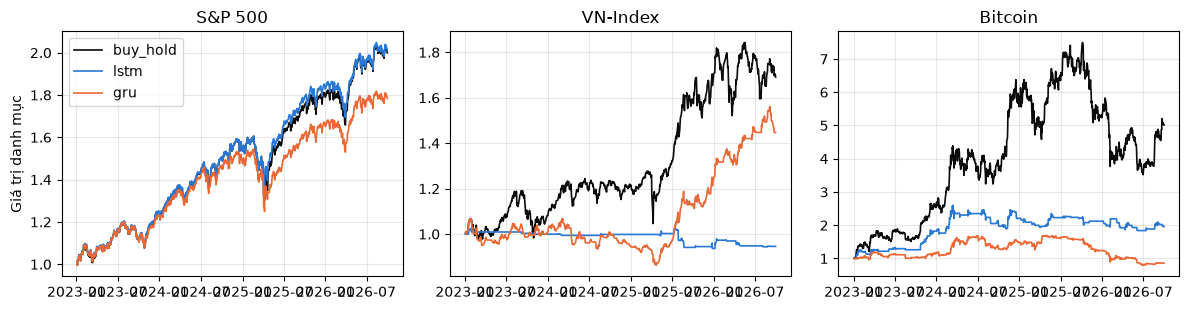

In [14]:
rows = []
for name in DATASETS:
    for key, b in analysis['backtest'][name].items():
        rows.append({'Chỉ số': NAMES[name], 'Chiến lược': key, 'Lợi suất năm trước phí': round(b['annual_return_gross'], 4),
                     'Lợi suất năm sau phí': round(b['annual_return'], 4), 'Sharpe': round(b['sharpe'], 2),
                     'Sụt giảm tối đa': round(b['max_drawdown'], 4), 'Thời gian nắm giữ': round(b['exposure'], 3),
                     'Số lần mua': b['entries']})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, name in zip(axes, DATASETS):
    eq = analysis['equity'][name]
    dates = pd.to_datetime(eq['dates'])
    for key, color in (('buy_hold', '#0b0b0b'), ('lstm', '#2a78d6'), ('gru', '#eb6834')):
        ax.plot(dates, eq[key], color=color, lw=1.2, label=key)
    ax.set_title(NAMES[name]); ax.grid(alpha=.3)
axes[0].set_ylabel('Giá trị danh mục'); axes[0].legend()
plt.tight_layout(); plt.show()

**Nhận xét kết quả backtest.** S&P 500: mua và giữ 20,5% mỗi năm; mạng hồi quy tốt nhất là LSTM với 21,1% trước phí và 20,6% sau phí; VN-Index: mua và giữ 15,3% mỗi năm; mạng hồi quy tốt nhất là GRU với 22,2% trước phí và 10,5% sau phí; Bitcoin: mua và giữ 53,8% mỗi năm; mạng hồi quy tốt nhất là LSTM với 24,6% trước phí và 19,7% sau phí. Sau phí giao dịch không chiến lược nào thắng mua và giữ một cách thuyết phục: ở S&P 500 mô hình tốt nhất gần như luôn nắm giữ nên chỉ ngang mua và giữ; ở VN-Index lợi thế trước phí bị phí giao dịch lấy đi; ở Bitcoin mọi mạng hồi quy đều thua mua và giữ ngay cả trước phí. ROC-AUC cao hơn 0,5 một chút chưa đủ để sinh lời.

# Phần B · Cài đặt RNN 5 lớp hồi quy + Dense bằng Scratch, Keras, PyTorch

**RNN: năm lớp hồi quy + Dense, Scratch – Keras – PyTorch.** Cùng cấu trúc **công thức → hàm → code → kết quả → giải thích**. Dữ liệu VN-Index thật; để chạy nhanh chỉ dùng 256 mẫu train, 128 validation, 256 test và 3 epoch (thực nghiệm minh họa trên tập con).

In [15]:
# Cell RNN-01
import os, sys, json, time, inspect, copy
from pathlib import Path
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[key] = '2'
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'src/tieuluan').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
OUT = ROOT/'results/tieuluan/complete/notebooks'
OUT.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)

Project: E:\WINDOW\Project\intelligent-system-assignment-01


## Dữ liệu và kiểu đầu vào–đầu ra

    Giữ đúng ranh giới thời gian của bộ dữ liệu đã chuẩn hóa từ train.
    Lấy 256 mẫu cuối của train, 128 mẫu đầu val và 256 mẫu đầu test.
    In ngày quan sát/ngày nhãn và phân bố lớp để người xem kiểm tra.
    `train_x`, `val_x`, `test_x` là tensor; nhãn có shape B × 1.

In [16]:
# Cell RNN-02
KIND = 'rnn'
representation = 'image' if KIND == 'cnn' else 'sequence'
with np.load(ROOT/'data/tieuluan/processed/vnindex.npz') as archive:
    data = {}
    ranges = {'train':slice(-256,None), 'val':slice(0,128),
              'test':slice(0,256)}
    inventory = []
    for split, selection in ranges.items():
        data[split+'_x'] = archive[split+'_'+representation][selection].copy()
        data[split+'_y'] = archive[split+'_y'][selection].reshape(-1,1).copy()
        dates = archive[split+'_date'][selection]
        targets = archive[split+'_target_date'][selection]
        inventory.append({'split':split, 'n':len(dates),
            'first':str(dates[0]), 'last_target':str(targets[-1]),
            'positive':int(data[split+'_y'].sum())})
    assert archive['train_target_date'].max() < archive['val_date'].min()
    assert archive['val_target_date'].max() < archive['test_date'].min()
display(pd.DataFrame(inventory))
print('X:', data['train_x'].shape, 'y:', data['train_y'].shape)

,split,n,first,last_target,positive
0,train,256,2018-12-20,2019-12-31,129
1,val,128,2020-01-02,2020-07-10,74
2,test,256,2023-01-03,2024-01-11,153


X: (256, 20, 1) y: (256, 1)


## B1. Biểu diễn mạng là hợp các hàm

    CNN: z = D6 ∘ ReLU ∘ D5 ∘ Flatten ∘ ReLU ∘ C4 ∘ ReLU ∘ C3
    ∘ ReLU ∘ C2 ∘ ReLU ∘ C1 (X).

    RNN/LSTM: z = Dense ∘ LastStep ∘ Cell5 ∘ Cell4 ∘ Cell3 ∘ Cell2 ∘ Cell1 (X).

    Đọc từ phải sang trái. CNN có 4 Conv + 2 Dense; RNN/LSTM có 5 lớp hồi quy
    + 1 Dense. ReLU, Flatten, LastStep và số bước thời gian không được đếm thành
    lớp học được. Xác suất chỉ tính bằng sigmoid sau logit.

In [17]:
# Cell RNN-03
from src.tieuluan.scratch.core import Sequential
from src.tieuluan.scratch.layers import Conv2d, Dense, Flatten, ReLU
from src.tieuluan.scratch.recurrent import SimpleRNN, LSTM, LastStep

def scratch_deep(kind, seed=42):
    rng = np.random.default_rng(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [Conv2d(cin, cout, 3, rng=rng), ReLU()]
        return Sequential(*layers, Flatten(),
                          Dense(8*12*12, 8, rng=rng), ReLU(),
                          Dense(8, 1, rng=rng))
    cell = {'rnn': SimpleRNN, 'lstm': LSTM}[kind]
    layers = [cell(1, 8, rng=rng)]
    layers += [cell(8, 8, rng=rng) for _ in range(4)]
    return Sequential(*layers, LastStep(), Dense(8, 1, rng=rng))

### Giải thích `scratch_deep`

    Đầu vào là `kind` và seed; đầu ra là Sequential tự viết bằng NumPy.
    CNN: mỗi Conv giảm cạnh ảnh hai đơn vị, từ 20 xuống 12, nên Dense nhận
    8 × 12 × 12 = 1.152 giá trị. RNN/LSTM: lớp đầu nhận một đặc trưng,
    các lớp sau nhận tám chiều; chỉ lấy bước cuối sau lớp thứ năm.
    Mỗi lớp Scratch có forward/backward riêng, không gọi autograd.

In [18]:
# Cell RNN-04
def keras_deep(kind, seed=42):
    import keras
    keras.utils.set_random_seed(seed)
    if kind == 'cnn':
        x = keras.Input((1, 20, 20))
        z = keras.layers.Permute((2, 3, 1))(x)
        for width in [4, 4, 8, 8]:
            z = keras.layers.Conv2D(width, 3, activation='relu')(z)
        z = keras.layers.Permute((3, 1, 2))(z)
        z = keras.layers.Flatten()(z)
        z = keras.layers.Dense(8, activation='relu')(z)
    else:
        x = keras.Input((20, 1))
        z = x
        cell = {'rnn': keras.layers.SimpleRNN,
                'lstm': keras.layers.LSTM}[kind]
        for depth in range(5):
            z = cell(8, return_sequences=(depth < 4))(z)
    return keras.Model(x, keras.layers.Dense(1)(z))

### Giải thích `keras_deep`

    Keras dùng Functional API. Permute đổi NCHW sang NHWC cho Conv và đưa về
    NCHW trước Flatten để khớp thứ tự với Scratch. Với hồi quy, bốn lớp đầu
    `return_sequences=True`; lớp cuối trả vector. Dense cuối chưa sigmoid,
    để dùng BCE trực tiếp từ logit.

In [19]:
# Cell RNN-05
def torch_deep(kind, seed=42):
    import torch
    from torch import nn
    torch.manual_seed(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [nn.Conv2d(cin, cout, 3), nn.ReLU()]
        return nn.Sequential(*layers, nn.Flatten(),
                             nn.Linear(8*12*12, 8), nn.ReLU(),
                             nn.Linear(8, 1))

    class Stacked(nn.Module):
        def __init__(self):
            super().__init__()
            cell = {'rnn': nn.RNN, 'lstm': nn.LSTM}[kind]
            self.cells = nn.ModuleList([cell(1, 8, batch_first=True)])
            self.cells.extend([cell(8, 8, batch_first=True)
                               for _ in range(4)])
            self.head = nn.Linear(8, 1)

        def forward(self, x):
            for cell in self.cells:
                x, _ = cell(x)
            return self.head(x[:, -1])
    return Stacked()

### Giải thích `torch_deep` và `Stacked.forward`

    CNN dùng nn.Sequential; hồi quy dùng ModuleList. Mỗi cell trả về toàn bộ
    chuỗi và trạng thái cuối; forward truyền chuỗi sang cell tiếp theo,
    rồi lấy x[:, -1] đưa qua Linear. `batch_first=True` giữ shape B × T × D.

In [20]:
# Cell RNN-06
def align_weights(source, target, framework, kind):
    """Same effective weights and same trainable parameter counts."""
    weighted = [l for l in source.layers if l.parameters()]
    if framework == 'keras':
        targets = [l for l in target.layers if l.weights]
        for s, t in zip(weighted, targets, strict=True):
            if isinstance(s, Conv2d):
                t.set_weights([s.weight.value.transpose(2, 3, 1, 0),
                               s.bias.value])
            elif isinstance(s, Dense):
                t.set_weights([s.weight.value.T, s.bias.value])
            else:
                t.set_weights([s.weight_ih.value.T,
                               s.weight_hh.value.T,
                               s.bias_ih.value + s.bias_hh.value])
    else:
        import torch
        with torch.no_grad():
            for s, t in zip(source.parameters(), target.parameters(),
                            strict=True):
                t.copy_(torch.from_numpy(s.value))
        if kind != 'cnn':
            for cell in target.cells:
                cell.bias_hh_l0.requires_grad_(False)
    if kind != 'cnn':
        for layer in weighted[:-1]:
            layer.bias_hh.grad[...] = 0

### Giải thích `align_weights`

    Cùng seed không bảo đảm cùng trọng số giữa ba thư viện. Hàm sao chép cùng
    trọng số hiệu dụng; đổi trục kernel Conv và chuyển vị Dense cho Keras.
    Với hồi quy, giữ bias thứ hai bằng không để số tham số học khớp một bias
    của Keras. Kiểm tra logit ban đầu trong cell huấn luyện sẽ phát hiện lệch.

In [21]:
# Cell RNN-07
# Quan sát hợp hàm bằng cách in shape sau từng hàm, trên một mẫu thật.
trace_model = scratch_deep(KIND)
value = data['train_x'][:1]
trace = []
for index, layer in enumerate(trace_model.layers, 1):
    before = value.shape
    value = layer.forward(value)
    trace.append({'step':index, 'function':type(layer).__name__,
                  'input':str(before), 'output':str(value.shape)})
display(pd.DataFrame(trace))
print('Logit:', value.ravel())
print('Sigmoid:', (0.5*(1+np.tanh(value/2))).ravel())

,step,function,input,output
0,1,SimpleRNN,"(1, 20, 1)","(1, 20, 8)"
1,2,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
2,3,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
3,4,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
4,5,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
5,6,LastStep,"(1, 20, 8)","(1, 8)"
6,7,Dense,"(1, 8)","(1, 1)"


Logit: [-0.07917508]
Sigmoid: [0.48021656]


## B2. Giải thích bên trong hàm forward và backward

    Cell tiếp theo in mã thực của các lớp được dùng, giúp giải thích phép tính
    thay vì chỉ nói “gọi thư viện”. Với Dense: dW=GᵀX, db=sum(G), dX=GW.
    Với RNN/LSTM: backward chạy ngược thời gian và cộng gradient vào cùng trọng số.
    LSTM duy trì gradient ô nhớ c riêng với gradient trạng thái h.
    Đối chiếu từng dòng mã với công thức trong Chương 3/4.

In [22]:
# Cell RNN-08
primitives = [Conv2d, ReLU, Flatten, Dense] if KIND == 'cnn' else [
    SimpleRNN if KIND == 'rnn' else LSTM, LastStep, Dense]
for primitive in primitives:
    print(inspect.getsource(primitive))

class SimpleRNN(_Recurrent):
    """h_t = tanh(W_ih·x_t + b_ih + W_hh·h_{t-1} + b_hh)."""

    gates = 1

    def forward(self, x):
        n, t_len, _ = x.shape
        h = np.zeros((n, self.hidden_size), dtype=x.dtype)
        xw = x @ self.weight_ih.value.T + self.bias_ih.value
        hs = np.empty((n, t_len + 1, self.hidden_size), dtype=x.dtype)
        hs[:, 0] = h
        for t in range(t_len):
            h = np.tanh(xw[:, t] + h @ self.weight_hh.value.T + self.bias_hh.value)
            hs[:, t + 1] = h
        self._cache = (x, hs)
        return hs[:, 1:]

    def backward(self, grad):
        x, hs = self._cache
        n, t_len, d = x.shape
        dxw = np.empty((n, t_len, self.hidden_size), dtype=grad.dtype)
        dh_next = np.zeros((n, self.hidden_size), dtype=grad.dtype)
        w_hh = self.weight_hh.value
        for t in reversed(range(t_len)):
            da = (grad[:, t] + dh_next) * (1.0 - hs[:, t + 1] ** 2)
            self.weight_hh.grad += da.T @ hs[:, t]
   

In [23]:
# Cell RNN-09
def train_batch(model, framework, x, y, optimizer):
    """One actual optimization step, binary classification on logits."""
    if framework == 'scratch':
        from src.tieuluan.scratch.losses import BCEWithLogitsLoss
        from src.tieuluan.scratch.optim import clip_grad_norm
        model.train()
        model.zero_grad()
        loss = BCEWithLogitsLoss()
        value = loss.forward(model.forward(x), y)
        model.backward(loss.backward())
        # One effective bias, matching Keras and the frozen Torch bias.
        for layer in model.layers:
            if isinstance(layer, (SimpleRNN, LSTM)):
                layer.bias_hh.grad[...] = 0
        clip_grad_norm(model.parameters(), 1.0)
        optimizer.step()
        return value
    if framework == 'pytorch':
        import torch
        model.train()
        optimizer.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            model(torch.from_numpy(x)), torch.from_numpy(y))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        return float(loss.detach())
    import tensorflow as tf
    with tf.GradientTape() as tape:
        logits = model(x, training=True)
        loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            labels=y, logits=logits))
    grads = tape.gradient(loss, model.trainable_variables)
    grads, _ = tf.clip_by_global_norm(grads, 1.0)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return float(loss.numpy())

### Giải thích `train_batch`

    Thứ tự bắt buộc: zero_grad → forward → BCE từ logit → backward → cắt chuẩn
    gradient → Adam.step. Scratch tự tính đạo hàm; PyTorch dùng autograd;
    Keras dùng GradientTape. Xóa gradient bias phụ ở Scratch trước Adam.
    Nếu quên zero_grad, gradient các batch cộng dồn sai thiết kế.
    Nếu sigmoid trước BCEWithLogits, mất mát nhận sai kiểu đầu vào.

In [24]:
# Cell RNN-10
from sklearn.metrics import roc_auc_score, accuracy_score
from src.tieuluan.scratch.optim import Adam
import torch, keras
torch.set_num_threads(2)

def logits_of(model, framework, x):
    """Logit B x 1; suy luận không xây graph gradient."""
    if framework == 'scratch':
        model.eval()
        return model.forward(x)
    if framework == 'pytorch':
        model.eval()
        with torch.no_grad():
            return model(torch.from_numpy(x)).numpy()
    return model(x, training=False).numpy()

def binary_loss(z, y):
    """BCE ổn định số từ logit, không sigmoid hai lần."""
    return float(np.mean(np.logaddexp(0, z) - y*z))

def snapshot(model, framework):
    if framework == 'scratch':
        return model.state_dict()
    if framework == 'pytorch':
        return copy.deepcopy(model.state_dict())
    return [w.copy() for w in model.get_weights()]

def restore(model, framework, state):
    if framework in ['scratch', 'pytorch']:
        model.load_state_dict(state)
    else:
        model.set_weights(state)

def run_comparison(kind, data, epochs=3, batch_size=32):
    """Huấn luyện trên train, chọn checkpoint bằng val, đọc test ở cuối."""
    models = {'scratch': scratch_deep(kind),
              'keras': keras_deep(kind),
              'pytorch': torch_deep(kind)}
    for fw in ['keras', 'pytorch']:
        align_weights(models['scratch'], models[fw], fw, kind)
    optimizers = {
        'scratch': Adam(models['scratch'].parameters(), lr=0.001),
        'keras': keras.optimizers.Adam(learning_rate=0.001, epsilon=1e-8),
        'pytorch': torch.optim.Adam(
            [p for p in models['pytorch'].parameters() if p.requires_grad],
            lr=0.001, eps=1e-8)}
    reference = logits_of(models['scratch'], 'scratch', data['train_x'][:4])
    rows, curves, predictions = [], {}, {}
    for fw, model in models.items():
        diff = float(np.max(np.abs(
            logits_of(model, fw, data['train_x'][:4])-reference)))
        assert diff < 1e-4
        best_loss, best_state, best_epoch = float('inf'), None, 0
        history = []
        # Cùng thứ tự mini-batch giữa các framework.
        rng = np.random.default_rng(2026)
        start = time.perf_counter()
        for epoch in range(epochs):
            order = rng.permutation(len(data['train_y']))
            losses = []
            for i in range(0, len(order), batch_size):
                ids = order[i:i+batch_size]
                losses.append(train_batch(model, fw,
                    data['train_x'][ids], data['train_y'][ids],
                    optimizers[fw]))
            val_loss = binary_loss(
                logits_of(model, fw, data['val_x']), data['val_y'])
            history.append({'epoch':epoch+1,
                'train_loss':float(np.mean(losses)), 'val_loss':val_loss})
            if val_loss < best_loss:
                best_loss = val_loss
                best_state = snapshot(model, fw)
                best_epoch = epoch+1
        restore(model, fw, best_state)
        # Test chỉ được đánh giá sau khi chọn checkpoint bằng validation.
        z = logits_of(model, fw, data['test_x']).reshape(-1)
        probability = 0.5*(1+np.tanh(z/2))
        target = data['test_y'].reshape(-1)
        assert np.isfinite(z).all()
        rows.append({'kind':kind, 'framework':fw,
            'trainable_layers':6, 'train_n':len(data['train_y']),
            'val_n':len(data['val_y']), 'test_n':len(target),
            'epochs':epochs, 'best_epoch':best_epoch,
            'val_loss':best_loss, 'test_bce':binary_loss(z,target),
            'test_auc':float(roc_auc_score(target,probability)),
            'test_accuracy':float(accuracy_score(target,probability>=0.5)),
            'initial_max_error':diff,
            'seconds':time.perf_counter()-start})
        curves[fw] = history
        predictions[fw] = probability.tolist()
    return models, rows, curves, predictions

### Giải thích các hàm huấn luyện/đánh giá

    `logits_of` suy luận theo framework; `binary_loss` tính BCE ổn định số;
    `snapshot/restore` lưu và nạp checkpoint; `run_comparison` tạo ba mô hình
    cùng trọng số, học cùng thứ tự mini-batch và chọn checkpoint bằng val.
    Test được đánh giá sau khi chọn checkpoint, không dùng để chọn epoch.
    AUC của tập con ngắn chỉ phục vụ demo, không chứng minh lợi nhuận giao dịch.

In [25]:
# Cell RNN-11
models, rows, curves, predictions = run_comparison(KIND, data)
display(pd.DataFrame(rows).round(6))
payload = {'kind':KIND, 'dataset':'vnindex',
           'scope':'real-data subset demonstration; 3 epochs',
           'inventory':inventory, 'results':rows, 'history':curves,
           'predictions':predictions,
           'target':data['test_y'].reshape(-1).tolist()}
(OUT/(KIND+'_training.json')).write_text(
    json.dumps(payload,ensure_ascii=False,indent=2),encoding='utf8')

,kind,framework,trainable_layers,train_n,val_n,test_n,epochs,best_epoch,val_loss,test_bce,test_auc,test_accuracy,initial_max_error,seconds
0,rnn,scratch,6,256,128,256,3,3,0.736459,0.731804,0.481883,0.457031,0.0,0.263018
1,rnn,keras,6,256,128,256,3,3,0.736459,0.731804,0.481883,0.457031,0.0,21.405378
2,rnn,pytorch,6,256,128,256,3,3,0.736459,0.731804,0.481883,0.457031,0.0,0.575220


25481

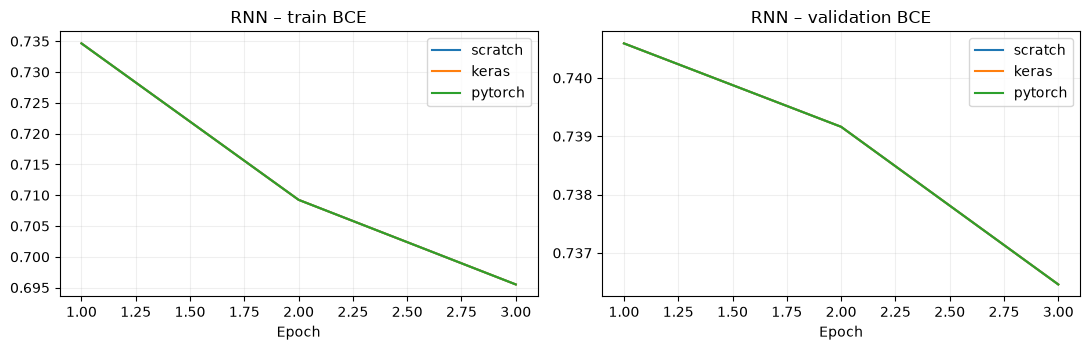

In [26]:
# Cell RNN-12
fig, axes = plt.subplots(1,2,figsize=(11,3.6))
for fw, history in curves.items():
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs,[r['train_loss'] for r in history],label=fw)
    axes[1].plot(epochs,[r['val_loss'] for r in history],label=fw)
axes[0].set_title(KIND.upper()+' – train BCE')
axes[1].set_title(KIND.upper()+' – validation BCE')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/(KIND+'_learning.png'),dpi=180)
plt.show()

## B3. Câu hỏi bảo vệ

    1. Hãy đọc biểu thức hợp hàm từ phải sang trái và chỉ shape tương ứng.
    2. Những lớp nào có tham số? Vì sao 20 thời điểm không thành 20 lớp?
    3. Vì sao phải align_weights trước khi so sánh?
    4. Gradient truyền qua từng hàm thế nào? Tại sao cần clipping?
    5. Loss giảm có bảo đảm AUC test tăng hay có lợi nhuận sau phí không?

    Kết quả trên tập con có thể dao động; phải báo cáo cả ba framework và
    giới hạn mẫu, không chọn riêng kết quả đẹp. Notebook không gửi lệnh giao dịch.

# Phần C · Cài đặt LSTM 5 lớp hồi quy + Dense bằng Scratch, Keras, PyTorch

**LSTM: năm lớp hồi quy + Dense, Scratch – Keras – PyTorch.** Giống phần B nhưng mỗi lớp là LSTM (cổng quên, cổng vào, cổng ra và ô nhớ). Cùng dữ liệu rút gọn và 3 epoch.

In [27]:
# Cell LSTM-01
import os, sys, json, time, inspect, copy
from pathlib import Path
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[key] = '2'
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'src/tieuluan').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
OUT = ROOT/'results/tieuluan/complete/notebooks'
OUT.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)

Project: E:\WINDOW\Project\intelligent-system-assignment-01


## Dữ liệu và kiểu đầu vào–đầu ra

    Giữ đúng ranh giới thời gian của bộ dữ liệu đã chuẩn hóa từ train.
    Lấy 256 mẫu cuối của train, 128 mẫu đầu val và 256 mẫu đầu test.
    In ngày quan sát/ngày nhãn và phân bố lớp để người xem kiểm tra.
    `train_x`, `val_x`, `test_x` là tensor; nhãn có shape B × 1.

In [28]:
# Cell LSTM-02
KIND = 'lstm'
representation = 'image' if KIND == 'cnn' else 'sequence'
with np.load(ROOT/'data/tieuluan/processed/vnindex.npz') as archive:
    data = {}
    ranges = {'train':slice(-256,None), 'val':slice(0,128),
              'test':slice(0,256)}
    inventory = []
    for split, selection in ranges.items():
        data[split+'_x'] = archive[split+'_'+representation][selection].copy()
        data[split+'_y'] = archive[split+'_y'][selection].reshape(-1,1).copy()
        dates = archive[split+'_date'][selection]
        targets = archive[split+'_target_date'][selection]
        inventory.append({'split':split, 'n':len(dates),
            'first':str(dates[0]), 'last_target':str(targets[-1]),
            'positive':int(data[split+'_y'].sum())})
    assert archive['train_target_date'].max() < archive['val_date'].min()
    assert archive['val_target_date'].max() < archive['test_date'].min()
display(pd.DataFrame(inventory))
print('X:', data['train_x'].shape, 'y:', data['train_y'].shape)

,split,n,first,last_target,positive
0,train,256,2018-12-20,2019-12-31,129
1,val,128,2020-01-02,2020-07-10,74
2,test,256,2023-01-03,2024-01-11,153


X: (256, 20, 1) y: (256, 1)


## C1. Biểu diễn mạng là hợp các hàm

    CNN: z = D6 ∘ ReLU ∘ D5 ∘ Flatten ∘ ReLU ∘ C4 ∘ ReLU ∘ C3
    ∘ ReLU ∘ C2 ∘ ReLU ∘ C1 (X).

    RNN/LSTM: z = Dense ∘ LastStep ∘ Cell5 ∘ Cell4 ∘ Cell3 ∘ Cell2 ∘ Cell1 (X).

    Đọc từ phải sang trái. CNN có 4 Conv + 2 Dense; RNN/LSTM có 5 lớp hồi quy
    + 1 Dense. ReLU, Flatten, LastStep và số bước thời gian không được đếm thành
    lớp học được. Xác suất chỉ tính bằng sigmoid sau logit.

In [29]:
# Cell LSTM-03
from src.tieuluan.scratch.core import Sequential
from src.tieuluan.scratch.layers import Conv2d, Dense, Flatten, ReLU
from src.tieuluan.scratch.recurrent import SimpleRNN, LSTM, LastStep

def scratch_deep(kind, seed=42):
    rng = np.random.default_rng(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [Conv2d(cin, cout, 3, rng=rng), ReLU()]
        return Sequential(*layers, Flatten(),
                          Dense(8*12*12, 8, rng=rng), ReLU(),
                          Dense(8, 1, rng=rng))
    cell = {'rnn': SimpleRNN, 'lstm': LSTM}[kind]
    layers = [cell(1, 8, rng=rng)]
    layers += [cell(8, 8, rng=rng) for _ in range(4)]
    return Sequential(*layers, LastStep(), Dense(8, 1, rng=rng))

### Giải thích `scratch_deep`

    Đầu vào là `kind` và seed; đầu ra là Sequential tự viết bằng NumPy.
    CNN: mỗi Conv giảm cạnh ảnh hai đơn vị, từ 20 xuống 12, nên Dense nhận
    8 × 12 × 12 = 1.152 giá trị. RNN/LSTM: lớp đầu nhận một đặc trưng,
    các lớp sau nhận tám chiều; chỉ lấy bước cuối sau lớp thứ năm.
    Mỗi lớp Scratch có forward/backward riêng, không gọi autograd.

In [30]:
# Cell LSTM-04
def keras_deep(kind, seed=42):
    import keras
    keras.utils.set_random_seed(seed)
    if kind == 'cnn':
        x = keras.Input((1, 20, 20))
        z = keras.layers.Permute((2, 3, 1))(x)
        for width in [4, 4, 8, 8]:
            z = keras.layers.Conv2D(width, 3, activation='relu')(z)
        z = keras.layers.Permute((3, 1, 2))(z)
        z = keras.layers.Flatten()(z)
        z = keras.layers.Dense(8, activation='relu')(z)
    else:
        x = keras.Input((20, 1))
        z = x
        cell = {'rnn': keras.layers.SimpleRNN,
                'lstm': keras.layers.LSTM}[kind]
        for depth in range(5):
            z = cell(8, return_sequences=(depth < 4))(z)
    return keras.Model(x, keras.layers.Dense(1)(z))

### Giải thích `keras_deep`

    Keras dùng Functional API. Permute đổi NCHW sang NHWC cho Conv và đưa về
    NCHW trước Flatten để khớp thứ tự với Scratch. Với hồi quy, bốn lớp đầu
    `return_sequences=True`; lớp cuối trả vector. Dense cuối chưa sigmoid,
    để dùng BCE trực tiếp từ logit.

In [31]:
# Cell LSTM-05
def torch_deep(kind, seed=42):
    import torch
    from torch import nn
    torch.manual_seed(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [nn.Conv2d(cin, cout, 3), nn.ReLU()]
        return nn.Sequential(*layers, nn.Flatten(),
                             nn.Linear(8*12*12, 8), nn.ReLU(),
                             nn.Linear(8, 1))

    class Stacked(nn.Module):
        def __init__(self):
            super().__init__()
            cell = {'rnn': nn.RNN, 'lstm': nn.LSTM}[kind]
            self.cells = nn.ModuleList([cell(1, 8, batch_first=True)])
            self.cells.extend([cell(8, 8, batch_first=True)
                               for _ in range(4)])
            self.head = nn.Linear(8, 1)

        def forward(self, x):
            for cell in self.cells:
                x, _ = cell(x)
            return self.head(x[:, -1])
    return Stacked()

### Giải thích `torch_deep` và `Stacked.forward`

    CNN dùng nn.Sequential; hồi quy dùng ModuleList. Mỗi cell trả về toàn bộ
    chuỗi và trạng thái cuối; forward truyền chuỗi sang cell tiếp theo,
    rồi lấy x[:, -1] đưa qua Linear. `batch_first=True` giữ shape B × T × D.

In [32]:
# Cell LSTM-06
def align_weights(source, target, framework, kind):
    """Same effective weights and same trainable parameter counts."""
    weighted = [l for l in source.layers if l.parameters()]
    if framework == 'keras':
        targets = [l for l in target.layers if l.weights]
        for s, t in zip(weighted, targets, strict=True):
            if isinstance(s, Conv2d):
                t.set_weights([s.weight.value.transpose(2, 3, 1, 0),
                               s.bias.value])
            elif isinstance(s, Dense):
                t.set_weights([s.weight.value.T, s.bias.value])
            else:
                t.set_weights([s.weight_ih.value.T,
                               s.weight_hh.value.T,
                               s.bias_ih.value + s.bias_hh.value])
    else:
        import torch
        with torch.no_grad():
            for s, t in zip(source.parameters(), target.parameters(),
                            strict=True):
                t.copy_(torch.from_numpy(s.value))
        if kind != 'cnn':
            for cell in target.cells:
                cell.bias_hh_l0.requires_grad_(False)
    if kind != 'cnn':
        for layer in weighted[:-1]:
            layer.bias_hh.grad[...] = 0

### Giải thích `align_weights`

    Cùng seed không bảo đảm cùng trọng số giữa ba thư viện. Hàm sao chép cùng
    trọng số hiệu dụng; đổi trục kernel Conv và chuyển vị Dense cho Keras.
    Với hồi quy, giữ bias thứ hai bằng không để số tham số học khớp một bias
    của Keras. Kiểm tra logit ban đầu trong cell huấn luyện sẽ phát hiện lệch.

In [33]:
# Cell LSTM-07
# Quan sát hợp hàm bằng cách in shape sau từng hàm, trên một mẫu thật.
trace_model = scratch_deep(KIND)
value = data['train_x'][:1]
trace = []
for index, layer in enumerate(trace_model.layers, 1):
    before = value.shape
    value = layer.forward(value)
    trace.append({'step':index, 'function':type(layer).__name__,
                  'input':str(before), 'output':str(value.shape)})
display(pd.DataFrame(trace))
print('Logit:', value.ravel())
print('Sigmoid:', (0.5*(1+np.tanh(value/2))).ravel())

,step,function,input,output
0,1,LSTM,"(1, 20, 1)","(1, 20, 8)"
1,2,LSTM,"(1, 20, 8)","(1, 20, 8)"
2,3,LSTM,"(1, 20, 8)","(1, 20, 8)"
3,4,LSTM,"(1, 20, 8)","(1, 20, 8)"
4,5,LSTM,"(1, 20, 8)","(1, 20, 8)"
5,6,LastStep,"(1, 20, 8)","(1, 8)"
6,7,Dense,"(1, 8)","(1, 1)"


Logit: [0.00264347]
Sigmoid: [0.50066084]


## C2. Giải thích bên trong hàm forward và backward

    Cell tiếp theo in mã thực của các lớp được dùng, giúp giải thích phép tính
    thay vì chỉ nói “gọi thư viện”. Với Dense: dW=GᵀX, db=sum(G), dX=GW.
    Với RNN/LSTM: backward chạy ngược thời gian và cộng gradient vào cùng trọng số.
    LSTM duy trì gradient ô nhớ c riêng với gradient trạng thái h.
    Đối chiếu từng dòng mã với công thức trong Chương 3/4.

In [34]:
# Cell LSTM-08
primitives = [Conv2d, ReLU, Flatten, Dense] if KIND == 'cnn' else [
    SimpleRNN if KIND == 'rnn' else LSTM, LastStep, Dense]
for primitive in primitives:
    print(inspect.getsource(primitive))

class LSTM(_Recurrent):
    """LSTM (Hochreiter & Schmidhuber, 1997; cổng quên của Gers et al., 2000).

    i = σ(·), f = σ(·), g = tanh(·), o = σ(·);  c_t = f⊙c_{t-1} + i⊙g;  h_t = o⊙tanh(c_t).
    """

    gates = 4

    def __init__(self, input_size, hidden_size, *, rng=None, dtype=np.float32, forget_bias: float = 1.0):
        super().__init__(input_size, hidden_size, rng=rng, dtype=dtype, forget_bias=forget_bias)

    def forward(self, x):
        n, t_len, _ = x.shape
        hd = self.hidden_size
        xw = x @ self.weight_ih.value.T + self.bias_ih.value
        h = np.zeros((n, hd), dtype=x.dtype)
        c = np.zeros((n, hd), dtype=x.dtype)
        hs = np.empty((n, t_len + 1, hd), dtype=x.dtype); hs[:, 0] = h
        cs = np.empty((n, t_len + 1, hd), dtype=x.dtype); cs[:, 0] = c
        acts = np.empty((n, t_len, 4 * hd), dtype=x.dtype)
        tcs = np.empty((n, t_len, hd), dtype=x.dtype)
        for t in range(t_len):
            z = xw[:, t] + h @ self.weight_hh.value.T 

In [35]:
# Cell LSTM-09
def train_batch(model, framework, x, y, optimizer):
    """One actual optimization step, binary classification on logits."""
    if framework == 'scratch':
        from src.tieuluan.scratch.losses import BCEWithLogitsLoss
        from src.tieuluan.scratch.optim import clip_grad_norm
        model.train()
        model.zero_grad()
        loss = BCEWithLogitsLoss()
        value = loss.forward(model.forward(x), y)
        model.backward(loss.backward())
        # One effective bias, matching Keras and the frozen Torch bias.
        for layer in model.layers:
            if isinstance(layer, (SimpleRNN, LSTM)):
                layer.bias_hh.grad[...] = 0
        clip_grad_norm(model.parameters(), 1.0)
        optimizer.step()
        return value
    if framework == 'pytorch':
        import torch
        model.train()
        optimizer.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            model(torch.from_numpy(x)), torch.from_numpy(y))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        return float(loss.detach())
    import tensorflow as tf
    with tf.GradientTape() as tape:
        logits = model(x, training=True)
        loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            labels=y, logits=logits))
    grads = tape.gradient(loss, model.trainable_variables)
    grads, _ = tf.clip_by_global_norm(grads, 1.0)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return float(loss.numpy())

### Giải thích `train_batch`

    Thứ tự bắt buộc: zero_grad → forward → BCE từ logit → backward → cắt chuẩn
    gradient → Adam.step. Scratch tự tính đạo hàm; PyTorch dùng autograd;
    Keras dùng GradientTape. Xóa gradient bias phụ ở Scratch trước Adam.
    Nếu quên zero_grad, gradient các batch cộng dồn sai thiết kế.
    Nếu sigmoid trước BCEWithLogits, mất mát nhận sai kiểu đầu vào.

In [36]:
# Cell LSTM-10
from sklearn.metrics import roc_auc_score, accuracy_score
from src.tieuluan.scratch.optim import Adam
import torch, keras
torch.set_num_threads(2)

def logits_of(model, framework, x):
    """Logit B x 1; suy luận không xây graph gradient."""
    if framework == 'scratch':
        model.eval()
        return model.forward(x)
    if framework == 'pytorch':
        model.eval()
        with torch.no_grad():
            return model(torch.from_numpy(x)).numpy()
    return model(x, training=False).numpy()

def binary_loss(z, y):
    """BCE ổn định số từ logit, không sigmoid hai lần."""
    return float(np.mean(np.logaddexp(0, z) - y*z))

def snapshot(model, framework):
    if framework == 'scratch':
        return model.state_dict()
    if framework == 'pytorch':
        return copy.deepcopy(model.state_dict())
    return [w.copy() for w in model.get_weights()]

def restore(model, framework, state):
    if framework in ['scratch', 'pytorch']:
        model.load_state_dict(state)
    else:
        model.set_weights(state)

def run_comparison(kind, data, epochs=3, batch_size=32):
    """Huấn luyện trên train, chọn checkpoint bằng val, đọc test ở cuối."""
    models = {'scratch': scratch_deep(kind),
              'keras': keras_deep(kind),
              'pytorch': torch_deep(kind)}
    for fw in ['keras', 'pytorch']:
        align_weights(models['scratch'], models[fw], fw, kind)
    optimizers = {
        'scratch': Adam(models['scratch'].parameters(), lr=0.001),
        'keras': keras.optimizers.Adam(learning_rate=0.001, epsilon=1e-8),
        'pytorch': torch.optim.Adam(
            [p for p in models['pytorch'].parameters() if p.requires_grad],
            lr=0.001, eps=1e-8)}
    reference = logits_of(models['scratch'], 'scratch', data['train_x'][:4])
    rows, curves, predictions = [], {}, {}
    for fw, model in models.items():
        diff = float(np.max(np.abs(
            logits_of(model, fw, data['train_x'][:4])-reference)))
        assert diff < 1e-4
        best_loss, best_state, best_epoch = float('inf'), None, 0
        history = []
        # Cùng thứ tự mini-batch giữa các framework.
        rng = np.random.default_rng(2026)
        start = time.perf_counter()
        for epoch in range(epochs):
            order = rng.permutation(len(data['train_y']))
            losses = []
            for i in range(0, len(order), batch_size):
                ids = order[i:i+batch_size]
                losses.append(train_batch(model, fw,
                    data['train_x'][ids], data['train_y'][ids],
                    optimizers[fw]))
            val_loss = binary_loss(
                logits_of(model, fw, data['val_x']), data['val_y'])
            history.append({'epoch':epoch+1,
                'train_loss':float(np.mean(losses)), 'val_loss':val_loss})
            if val_loss < best_loss:
                best_loss = val_loss
                best_state = snapshot(model, fw)
                best_epoch = epoch+1
        restore(model, fw, best_state)
        # Test chỉ được đánh giá sau khi chọn checkpoint bằng validation.
        z = logits_of(model, fw, data['test_x']).reshape(-1)
        probability = 0.5*(1+np.tanh(z/2))
        target = data['test_y'].reshape(-1)
        assert np.isfinite(z).all()
        rows.append({'kind':kind, 'framework':fw,
            'trainable_layers':6, 'train_n':len(data['train_y']),
            'val_n':len(data['val_y']), 'test_n':len(target),
            'epochs':epochs, 'best_epoch':best_epoch,
            'val_loss':best_loss, 'test_bce':binary_loss(z,target),
            'test_auc':float(roc_auc_score(target,probability)),
            'test_accuracy':float(accuracy_score(target,probability>=0.5)),
            'initial_max_error':diff,
            'seconds':time.perf_counter()-start})
        curves[fw] = history
        predictions[fw] = probability.tolist()
    return models, rows, curves, predictions

### Giải thích các hàm huấn luyện/đánh giá

    `logits_of` suy luận theo framework; `binary_loss` tính BCE ổn định số;
    `snapshot/restore` lưu và nạp checkpoint; `run_comparison` tạo ba mô hình
    cùng trọng số, học cùng thứ tự mini-batch và chọn checkpoint bằng val.
    Test được đánh giá sau khi chọn checkpoint, không dùng để chọn epoch.
    AUC của tập con ngắn chỉ phục vụ demo, không chứng minh lợi nhuận giao dịch.

In [37]:
# Cell LSTM-11
models, rows, curves, predictions = run_comparison(KIND, data)
display(pd.DataFrame(rows).round(6))
payload = {'kind':KIND, 'dataset':'vnindex',
           'scope':'real-data subset demonstration; 3 epochs',
           'inventory':inventory, 'results':rows, 'history':curves,
           'predictions':predictions,
           'target':data['test_y'].reshape(-1).tolist()}
(OUT/(KIND+'_training.json')).write_text(
    json.dumps(payload,ensure_ascii=False,indent=2),encoding='utf8')

,kind,framework,trainable_layers,train_n,val_n,test_n,epochs,best_epoch,val_loss,test_bce,test_auc,test_accuracy,initial_max_error,seconds
0,lstm,scratch,6,256,128,256,3,3,0.692489,0.692665,0.489339,0.597656,0.0,0.886181
1,lstm,keras,6,256,128,256,3,3,0.692490,0.692666,0.489435,0.597656,0.0,27.765232
2,lstm,pytorch,6,256,128,256,3,3,0.692489,0.692665,0.489339,0.597656,0.0,0.372858


25268

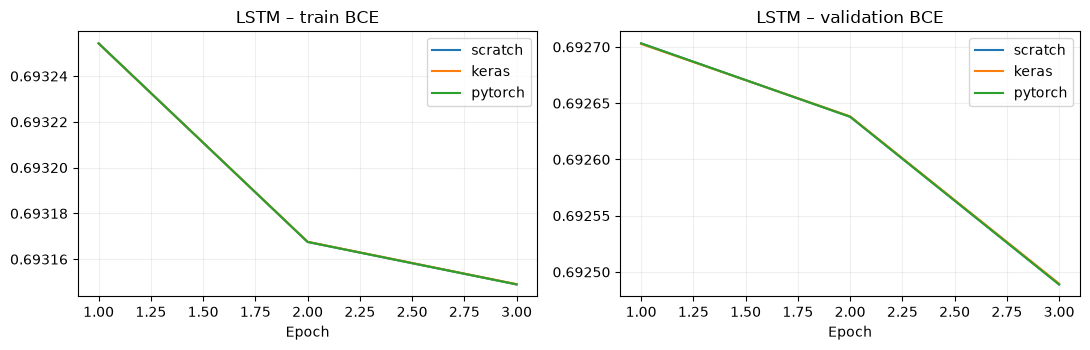

In [38]:
# Cell LSTM-12
fig, axes = plt.subplots(1,2,figsize=(11,3.6))
for fw, history in curves.items():
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs,[r['train_loss'] for r in history],label=fw)
    axes[1].plot(epochs,[r['val_loss'] for r in history],label=fw)
axes[0].set_title(KIND.upper()+' – train BCE')
axes[1].set_title(KIND.upper()+' – validation BCE')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/(KIND+'_learning.png'),dpi=180)
plt.show()

## C3. Câu hỏi bảo vệ

    1. Hãy đọc biểu thức hợp hàm từ phải sang trái và chỉ shape tương ứng.
    2. Những lớp nào có tham số? Vì sao 20 thời điểm không thành 20 lớp?
    3. Vì sao phải align_weights trước khi so sánh?
    4. Gradient truyền qua từng hàm thế nào? Tại sao cần clipping?
    5. Loss giảm có bảo đảm AUC test tăng hay có lợi nhuận sau phí không?

    Kết quả trên tập con có thể dao động; phải báo cáo cả ba framework và
    giới hạn mẫu, không chọn riêng kết quả đẹp. Notebook không gửi lệnh giao dịch.